# 04 · Avaliação, Seleção do Modelo e Explicabilidade
Compara os quatro modelos treinados em `03_modelagem.ipynb` nas métricas corretas para classes extremamente desbalanceadas, seleciona o modelo final, ajusta o threshold de decisão e explica as previsões com SHAP.

In [1]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score,
                              precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)

X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

## Comparação entre modelos

**Por que não usar acurácia**: com 0,17% de fraude no dataset, um modelo que sempre prevê "transação normal" acerta ~99,8% e é completamente inútil. As métricas de referência aqui são **Precision, Recall, F1 e PR-AUC** (Precision-Recall AUC) — PR-AUC é mais informativa que ROC-AUC quando a classe positiva é rara.

In [2]:
modelos = {
    'Logistic Regression': '../models/logistic_regression.pkl',
    'Random Forest': '../models/random_forest.pkl',
    'XGBoost (baseline)': '../models/xgboost_baseline.pkl',
    'XGBoost (tuned)': '../models/xgboost_tuned.pkl',
}

resumo = []
probs_por_modelo = {}
for nome, caminho in modelos.items():
    with open(caminho, 'rb') as f:
        modelo = pickle.load(f)
    probs = modelo.predict_proba(X_test)[:, 1]
    probs_por_modelo[nome] = probs
    pred = modelo.predict(X_test)
    rep = classification_report(y_test, pred, output_dict=True)
    resumo.append({
        'Modelo': nome,
        'Precision (fraude)': round(rep['1']['precision'], 3),
        'Recall (fraude)': round(rep['1']['recall'], 3),
        'F1 (fraude)': round(rep['1']['f1-score'], 3),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 3),
        'PR-AUC': round(average_precision_score(y_test, probs), 3),
    })

df_resumo = pd.DataFrame(resumo).sort_values('PR-AUC', ascending=False).reset_index(drop=True)
df_resumo

,Modelo,Precision (fraude),Recall (fraude),F1 (fraude),ROC-AUC,PR-AUC
0,XGBoost (tuned),0.872,0.768,0.816,0.966,0.814
1,XGBoost (baseline),0.908,0.761,0.828,0.976,0.810
2,Random Forest,0.876,0.746,0.806,0.945,0.808
3,Logistic Regression,0.051,0.887,0.096,0.963,0.691


In [3]:
df_resumo.to_csv('../reports/model_comparison.csv', index=False)

## Curvas Precision-Recall comparadas

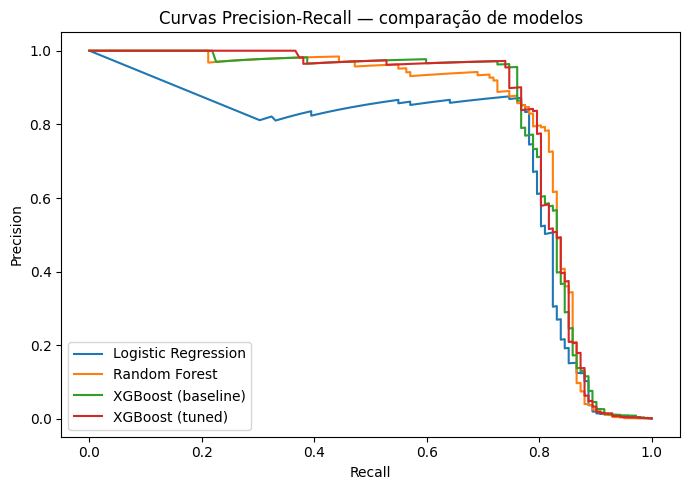

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
for nome, probs in probs_por_modelo.items():
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ax.plot(recall, precision, label=nome)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Curvas Precision-Recall — comparação de modelos')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/04_pr_curves.png', dpi=110)
plt.show()

## Seleção do modelo final

O modelo com maior **PR-AUC** é selecionado como final. Isso é mais robusto que escolher pelo F1 num único threshold, porque avalia o modelo em toda a faixa de possíveis pontos de corte.

In [5]:
melhor_nome = df_resumo.iloc[0]['Modelo']
print('Modelo selecionado:', melhor_nome)

with open(modelos[melhor_nome], 'rb') as f:
    modelo_final = pickle.load(f)
probs_final = probs_por_modelo[melhor_nome]

Modelo selecionado: XGBoost (tuned)


## Ajuste do threshold de decisão

O ponto de corte padrão (0.5) raramente é o melhor para classes raras. Aqui, o threshold é escolhido para **maximizar o F1** no conjunto de teste — em um cenário real, esse ponto de corte deveria refletir o custo de negócio (custo de investigar um falso positivo vs. custo de deixar passar uma fraude), não apenas uma métrica estatística.

In [6]:
precision, recall, thresholds = precision_recall_curve(y_test, probs_final)
f1_scores = 2 * precision * recall / (precision + recall + 1e-12)
melhor_idx = np.argmax(f1_scores[:-1])
melhor_threshold = thresholds[melhor_idx]

print(f'Threshold selecionado: {melhor_threshold:.4f}')
print(f'Precision: {precision[melhor_idx]:.3f} | Recall: {recall[melhor_idx]:.3f} | F1: {f1_scores[melhor_idx]:.3f}')

Threshold selecionado: 0.9614
Precision: 0.972 | Recall: 0.739 | F1: 0.840


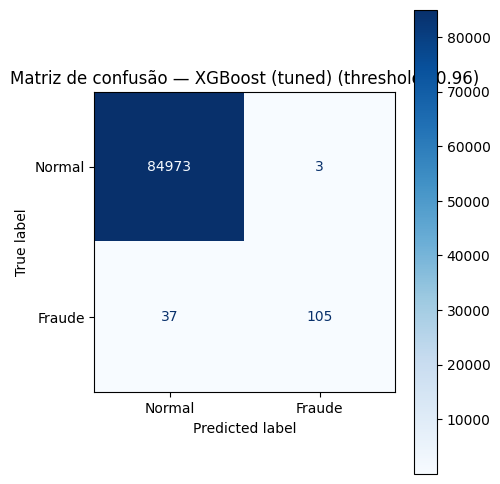

[[84973     3]
 [   37   105]]


In [7]:
pred_final = (probs_final >= melhor_threshold).astype(int)
cm = confusion_matrix(y_test, pred_final)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Fraude']).plot(ax=ax, cmap='Blues')
ax.set_title(f'Matriz de confusão — {melhor_nome} (threshold={melhor_threshold:.2f})')
plt.tight_layout()
plt.savefig('../reports/figures/05_confusion_matrix.png', dpi=110)
plt.show()
print(cm)

## Faixas de risco (para uso operacional)

Em vez de expor apenas uma decisão binária, o score de probabilidade é convertido em faixas de risco — mais próximo de como um sistema de revisão de fraude é usado na prática. Importante: são **recomendações de ação**, não decisões automáticas de bloqueio — a decisão final caberia a uma regra de negócio/analista.

In [8]:
def faixa_risco(score):
    if score < 0.40:
        return 'LOW'
    elif score < 0.70:
        return 'MEDIUM'
    elif score < 0.90:
        return 'HIGH'
    return 'CRITICAL'

risco = pd.Series(probs_final).apply(faixa_risco)
print(risco.value_counts())

LOW         84986
CRITICAL      109
MEDIUM         13
HIGH           10
Name: count, dtype: int64


## Explicabilidade (SHAP)

Explica quais variáveis mais influenciaram o score de risco do modelo final — essencial em aplicações de crédito/fraude tanto por confiança quanto por motivos regulatórios.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


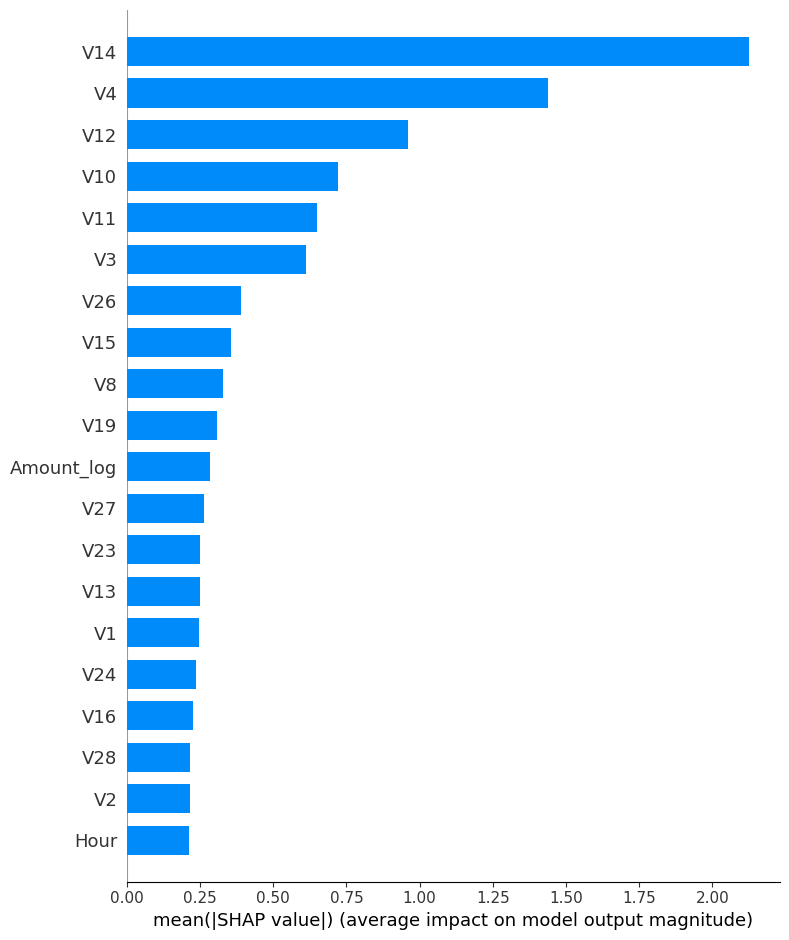

In [9]:
import shap

explainer = shap.TreeExplainer(modelo_final)
amostra = X_test.sample(200, random_state=42)
shap_values = explainer.shap_values(amostra)

shap.summary_plot(shap_values, amostra, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('../reports/figures/06_shap_importance.png', dpi=110)
plt.show()

## Nota de segurança: robustez e limitações

- **Ataques adversariais**: um agente malicioso com acesso ao comportamento do modelo poderia, em tese, desenhar transações que ficam abaixo do threshold. Modelos baseados em árvore/ensemble são mais difíceis (mas não impossíveis) de contornar do que um limiar simples por valor.
- **Concept drift**: o padrão de fraude muda com o tempo; este modelo reflete o comportamento capturado no período do dataset. Em produção, seria necessário monitorar a taxa de anomalias e re-treinar periodicamente.
- **Escopo do dado**: dataset público, anonimizado via PCA, com finalidade educacional. Nenhuma decisão financeira real é tomada por este projeto.

## Persistência do modelo final selecionado

In [10]:
import json
with open('../models/final_model.pkl', 'wb') as f:
    pickle.dump({'model': modelo_final, 'threshold': float(melhor_threshold),
                 'model_name': melhor_nome, 'features': list(X_test.columns)}, f)

with open('../reports/final_metrics.json', 'w') as f:
    json.dump({
        'modelo_selecionado': melhor_nome,
        'threshold': float(melhor_threshold),
        'precision': float(precision[melhor_idx]),
        'recall': float(recall[melhor_idx]),
        'f1': float(f1_scores[melhor_idx]),
        'pr_auc': float(df_resumo.iloc[0]['PR-AUC']),
        'roc_auc': float(df_resumo.iloc[0]['ROC-AUC']),
    }, f, indent=2)

print('Modelo final e métricas salvos em models/ e reports/')

Modelo final e métricas salvos em models/ e reports/


## Conclusão

O pipeline completo — da exploração à seleção final do modelo — está reproduzível nos quatro notebooks. Próximos passos possíveis estão descritos no README (seção V2: API própria, PostgreSQL, monitoramento contínuo, dashboard).